# LSA detection: 1D profile self-similarity

Straighten the taxiway, collapse it to a 1D gradient profile, tile at camera-footprint length, and compare all tiles (NCC).
Check: the two known ambiguous intersections (from `lsa_sat_correlation.ipynb`) should show an off-diagonal peak.

In [1]:
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
from lsa_helpers import rectify_strip, tile_profiles, tile_hog, tile_dino, ncc_matrix

In [2]:
# Satellite reference image
sat_ref = "../../datasets/KBCB_satellite/KBCB_partial_LSA.png"

sat_rgb = cv2.cvtColor(cv2.imread(sat_ref), cv2.COLOR_BGR2RGB)
sat_g = cv2.cvtColor(sat_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255

## Rectify taxiway strip

Strip (H, W): (81, 1864) | known along-track: [ 122. 1517.]


Text(0.5, 1.0, 'Strip outline + known ambiguous pair')

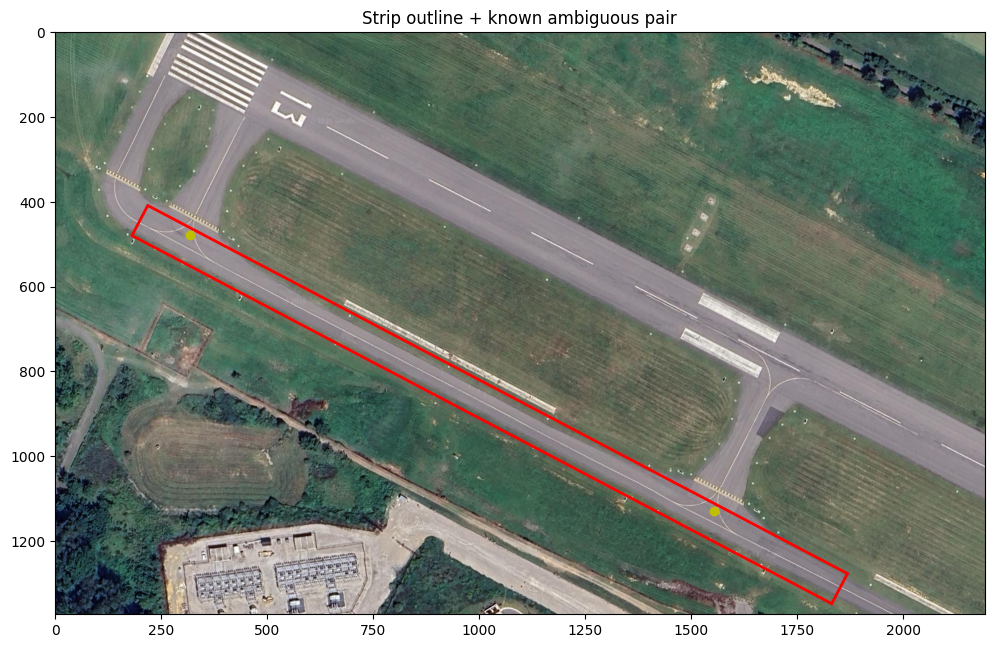

In [3]:
# Taxiway centerline endpoints (x, y), picked by eye from the white centerline marking
# NOTE: assumes a straight taxiway between p0 and p1
p0, p1 = (200, 444), (1850, 1312)
half_w = 40 # Strip half-width (px), ~ taxiway half-width

strip, u, n = rectify_strip(sat_g, p0, p1, half_w)

# Known ambiguous pair: trapezoid centroids from lsa_sat_correlation.ipynb -> along-track position (px)
known = np.array([[319, 479], [1554, 1129]])
s_known = (known - np.array(p0)) @ u
print("Strip (H, W):", strip.shape, "| known along-track:", s_known.round())

corners = np.array([p0 + half_w*n, p1 + half_w*n, p1 - half_w*n, p0 - half_w*n])
plt.figure(figsize=(12, 8))
plt.imshow(sat_rgb)
plt.gca().add_patch(plt.Polygon(corners, fill=False, ec='r', lw=2))
plt.plot(known[:, 0], known[:, 1], 'yo')
plt.title("Strip outline + known ambiguous pair")

## 1D gradient profile

Text(0, 0.5, 'Mean |grad|')

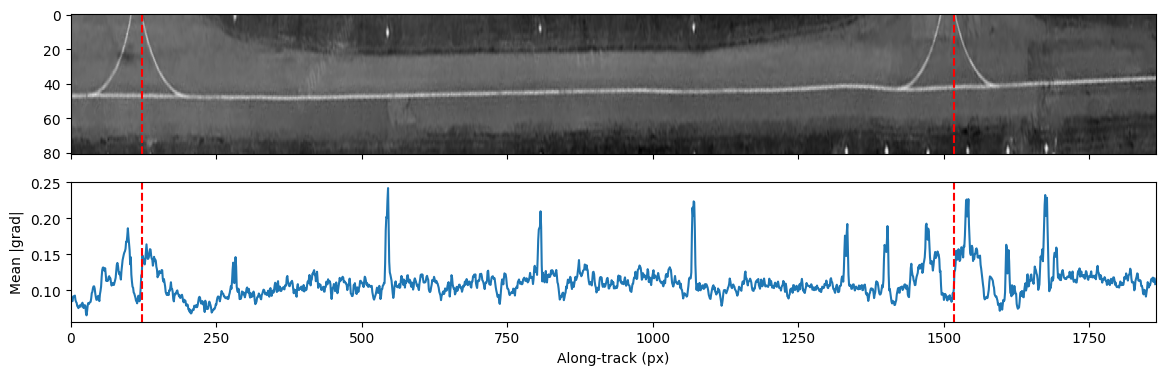

In [4]:
# Gradient magnitude, averaged across-track -> one value per along-track px
gx = cv2.Sobel(strip, cv2.CV_32F, 1, 0)
gy = cv2.Sobel(strip, cv2.CV_32F, 0, 1)
p = np.sqrt(gx**2 + gy**2).mean(axis=0)

fig, axs = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
axs[0].imshow(strip, cmap='gray', aspect='auto')
axs[1].plot(p)
for a in axs:
    for s in s_known:
        a.axvline(s, color='r', ls='--')
axs[1].set_xlabel("Along-track (px)")
axs[1].set_ylabel("Mean |grad|")

## Tile self-similarity

NCC at known pair: 0.48630488


Text(0.5, 1.0, 'Self-similarity (red x = known pair)')

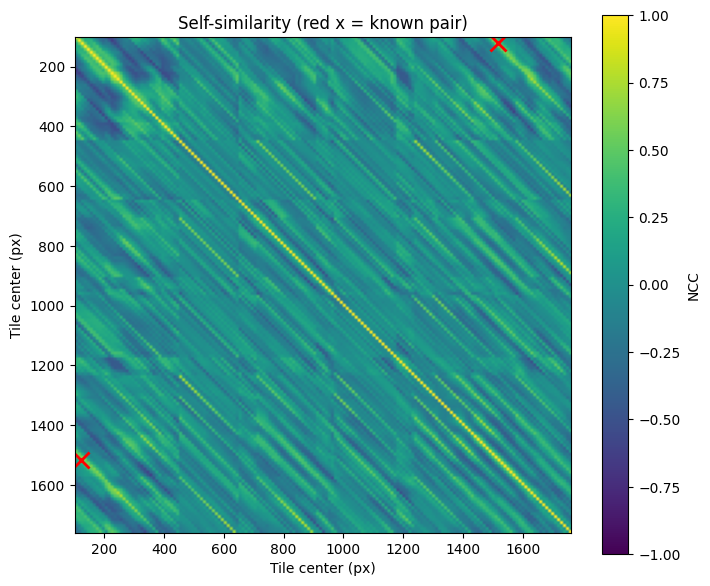

In [5]:
# Tile length ~ along-track length of the trapezoid footprints (~200 px)
# NOTE: fixed-length window, not the true trapezoid footprint, no altitude scaling
L, stride = 200, 10

tiles, starts = tile_profiles(p, L, stride)
S = ncc_matrix(tiles)
c = starts + L/2 # Tile centers (along-track px)

i_known = np.round((s_known - L/2) / stride).astype(int)
print("NCC at known pair:", S[i_known[0], i_known[1]])

plt.figure(figsize=(8, 7))
plt.imshow(S, cmap='viridis', vmin=-1, vmax=1, extent=[c[0], c[-1], c[-1], c[0]])
plt.plot(s_known[[0, 1]], s_known[[1, 0]], 'rx', ms=12, mew=2)
plt.colorbar(label="NCC")
plt.xlabel("Tile center (px)")
plt.ylabel("Tile center (px)")
plt.title("Self-similarity (red x = known pair)")

Text(0, 0.5, 'Best far NCC')

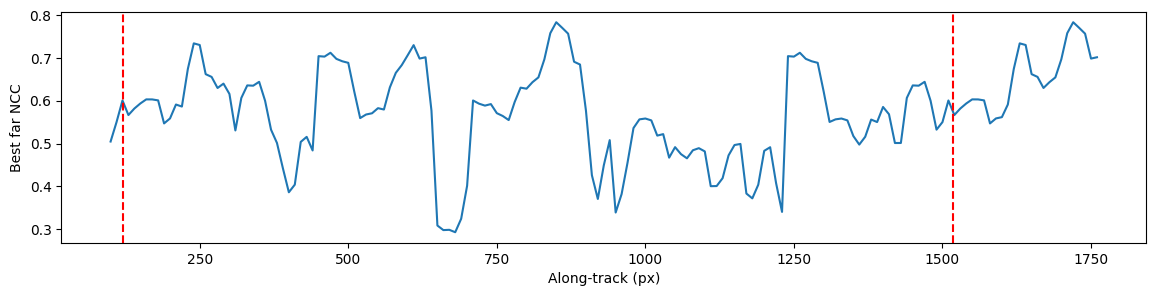

In [18]:
# Best match outside each tile's own neighborhood (|offset| > L) -> high = ambiguous
far = np.abs(starts[:, None] - starts[None, :]) > L 
best_far = np.where(far, S, -np.inf).max(axis=1)

plt.figure(figsize=(14, 3))
plt.plot(c, best_far)
for s in s_known:
    plt.axvline(s, color='r', ls='--')
plt.xlabel("Along-track (px)")
plt.ylabel("Best far NCC")

NCC at known pair (|gx|): 0.4505761


Text(0, 0.5, 'Best far NCC')

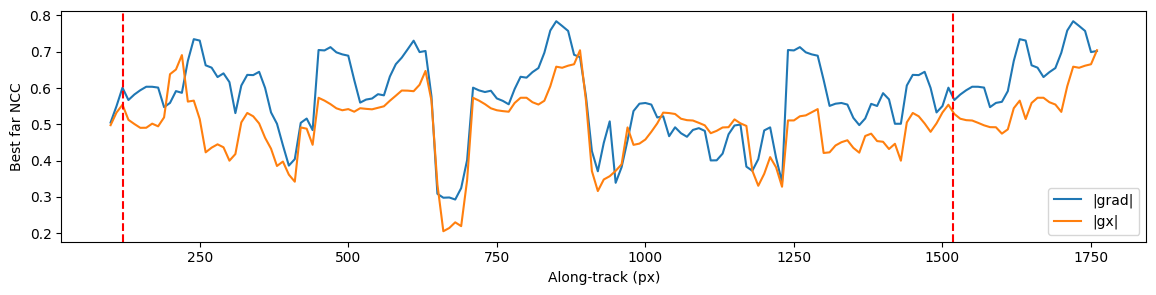

In [9]:
# Along-track gradient only: |gx| averaged across-track -> responds to edges crossing the taxiway
# NOTE: |gx| not signed gx, so bright->dark and dark->bright edges don't cancel in the row average
p_x = np.abs(gx).mean(axis=0)
S_x = ncc_matrix(tile_profiles(p_x, L, stride)[0])
print("NCC at known pair (|gx|):", S_x[i_known[0], i_known[1]])

plt.figure(figsize=(14, 3))
plt.plot(c, best_far, label='|grad|')
plt.plot(c, np.where(far, S_x, -np.inf).max(axis=1), label='|gx|')
for s in s_known:
    plt.axvline(s, color='r', ls='--')
plt.legend()
plt.xlabel("Along-track (px)")
plt.ylabel("Best far NCC")


## HOG tile self-similarity

HOG dims: 7776 | NCC at known pair: 0.53473073


Text(0.5, 1.0, 'HOG self-similarity (red x = known pair)')

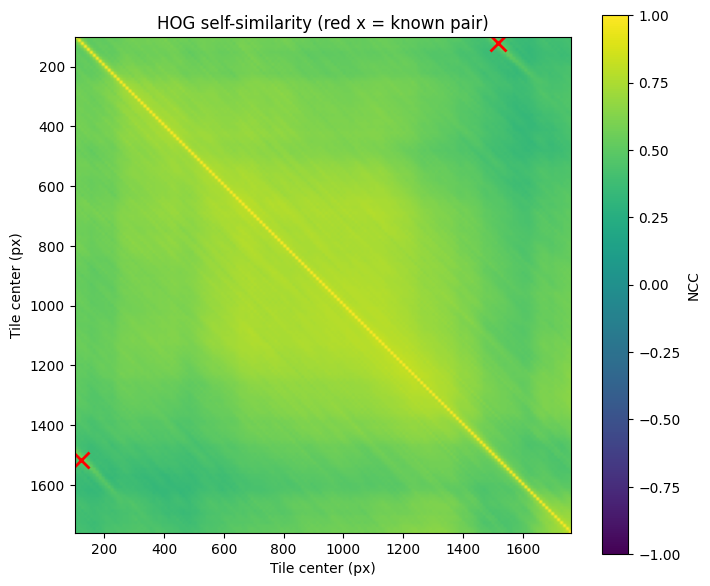

In [10]:
# HOG per 2D tile (same strip, L, stride as 1D) -> NCC between tile HOG vectors
feats_hog, starts_hog = tile_hog(strip, L, stride)
S_hog = ncc_matrix(feats_hog)
c_hog = starts_hog + L/2
print("HOG dims:", feats_hog.shape[1], "| NCC at known pair:", S_hog[i_known[0], i_known[1]])

plt.figure(figsize=(8, 7))
plt.imshow(S_hog, cmap='viridis', vmin=-1, vmax=1, extent=[c_hog[0], c_hog[-1], c_hog[-1], c_hog[0]])
plt.plot(s_known[[0, 1]], s_known[[1, 0]], 'rx', ms=12, mew=2)
plt.colorbar(label="NCC")
plt.xlabel("Tile center (px)")
plt.ylabel("Tile center (px)")
plt.title("HOG self-similarity (red x = known pair)")

Text(0, 0.5, 'Best far NCC (HOG)')

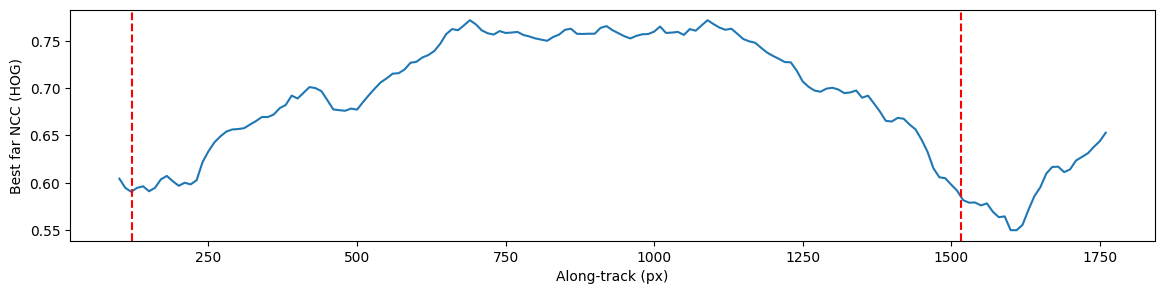

In [25]:
# Best far match, HOG
far = np.abs(starts[:, None] - starts[None, :]) > L + 0
best_far_hog = np.where(far, S_hog, -np.inf).max(axis=1)

plt.figure(figsize=(14, 3))
plt.plot(c_hog, best_far_hog)
for s in s_known:
    plt.axvline(s, color='r', ls='--')
plt.xlabel("Along-track (px)")
plt.ylabel("Best far NCC (HOG)")

NCC at known pair (HOG centered): 0.19877897


Text(0, 0.5, 'Best far NCC (HOG)')

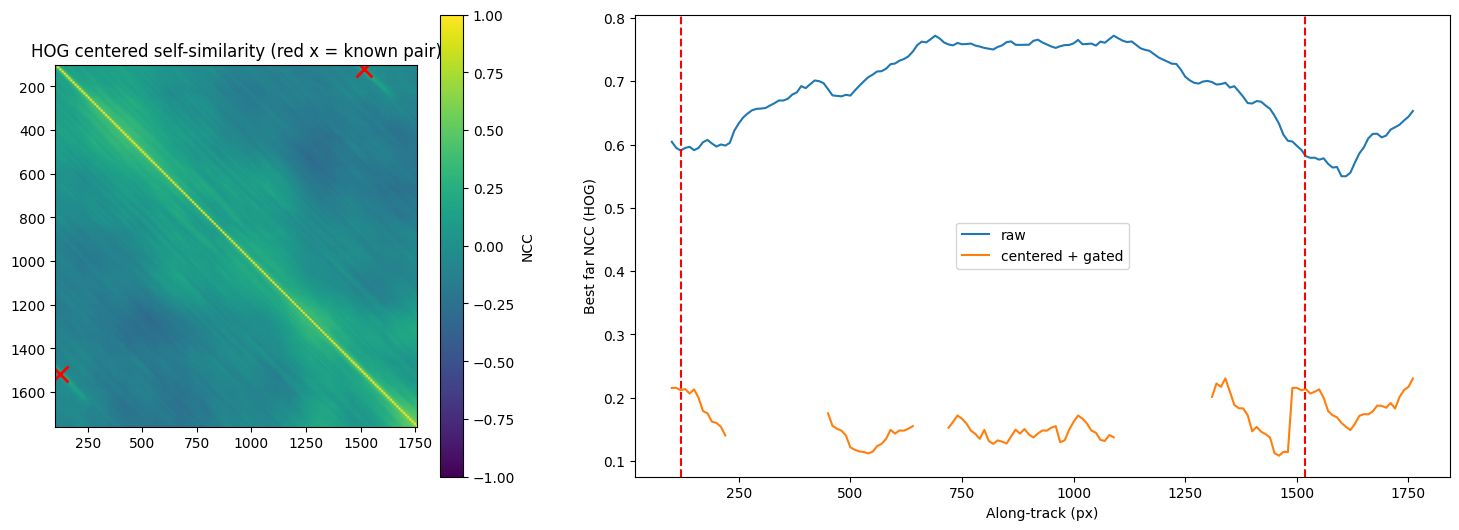

In [26]:
# HOG centered over all tiles (removes shared plain-taxiway component) + featureless tiles gated out
# NOTE: mean is over this strip's tiles only (same as DINOv2)
# Gate: tile energy = mean |gx| over the tile (edges crossing the taxiway); bottom 30% = degenerate, not scored
# NOTE: 30% threshold is arbitrary
S_hog_c = ncc_matrix(feats_hog - feats_hog.mean(axis=0))
print("NCC at known pair (HOG centered):", S_hog_c[i_known[0], i_known[1]])

energy = tile_profiles(p_x, L, stride)[0].mean(axis=1)
keep = energy > np.percentile(energy, 30)
best_far_c = np.where(far & keep[None, :], S_hog_c, -np.inf).max(axis=1)
best_far_c[~keep] = np.nan # Degenerate tiles left as gaps

fig, axs = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1.8]})
im = axs[0].imshow(S_hog_c, cmap='viridis', vmin=-1, vmax=1, extent=[c_hog[0], c_hog[-1], c_hog[-1], c_hog[0]])
axs[0].plot(s_known[[0, 1]], s_known[[1, 0]], 'rx', ms=12, mew=2)
axs[0].set_title("HOG centered self-similarity (red x = known pair)")
fig.colorbar(im, ax=axs[0], label="NCC")

axs[1].plot(c_hog, best_far_hog, label='raw')
axs[1].plot(c_hog, best_far_c, label='centered + gated')
for s in s_known:
    axs[1].axvline(s, color='r', ls='--')
axs[1].legend()
axs[1].set_xlabel("Along-track (px)")
axs[1].set_ylabel("Best far NCC (HOG)")

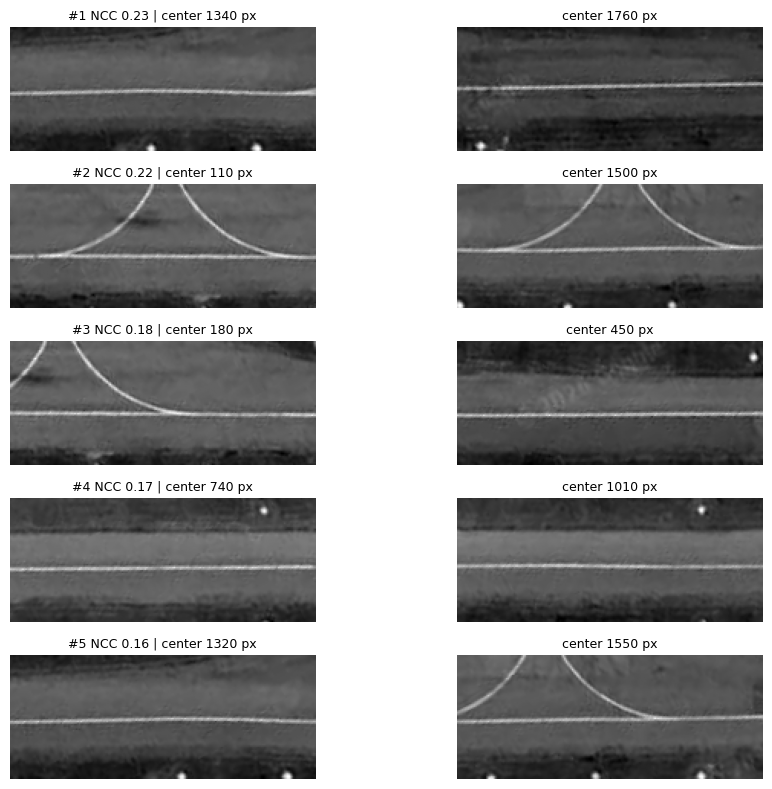

In [28]:
# Top-k distant pairs (HOG centered + gated), shown as side-by-side tiles
# Both tiles must pass the gate; skip pairs within L of an already-picked pair (same as DINOv2 cell)
# NOTE: grayscale strip (strip_rgb is only built in the DINOv2 section)
k = 5
iu, ju = np.where(np.triu(far & keep[:, None] & keep[None, :]))
order = np.argsort(S_hog_c[iu, ju])[::-1]

picked = []
for o in order:
    i, j = iu[o], ju[o]
    if all(abs(starts_hog[i] - starts_hog[a]) > L or abs(starts_hog[j] - starts_hog[b]) > L for a, b in picked):
        picked.append((i, j))
    if len(picked) == k:
        break

fig, axs = plt.subplots(k, 2, figsize=(10, 1.6*k))
for r, (i, j) in enumerate(picked):
    for a, t in zip(axs[r], (i, j)):
        a.imshow(strip[:, starts_hog[t]:starts_hog[t] + L], cmap='gray')
        a.set_title(f"center {c_hog[t]:.0f} px", fontsize=9)
        a.axis('off')
    axs[r, 0].set_title(f"#{r+1} NCC {S_hog_c[i, j]:.2f} | center {c_hog[i]:.0f} px", fontsize=9)
plt.tight_layout()

NCC at known pair (HOG centered, orientation-filtered): 0.26512313


Text(0, 0.5, 'Best far NCC (HOG)')

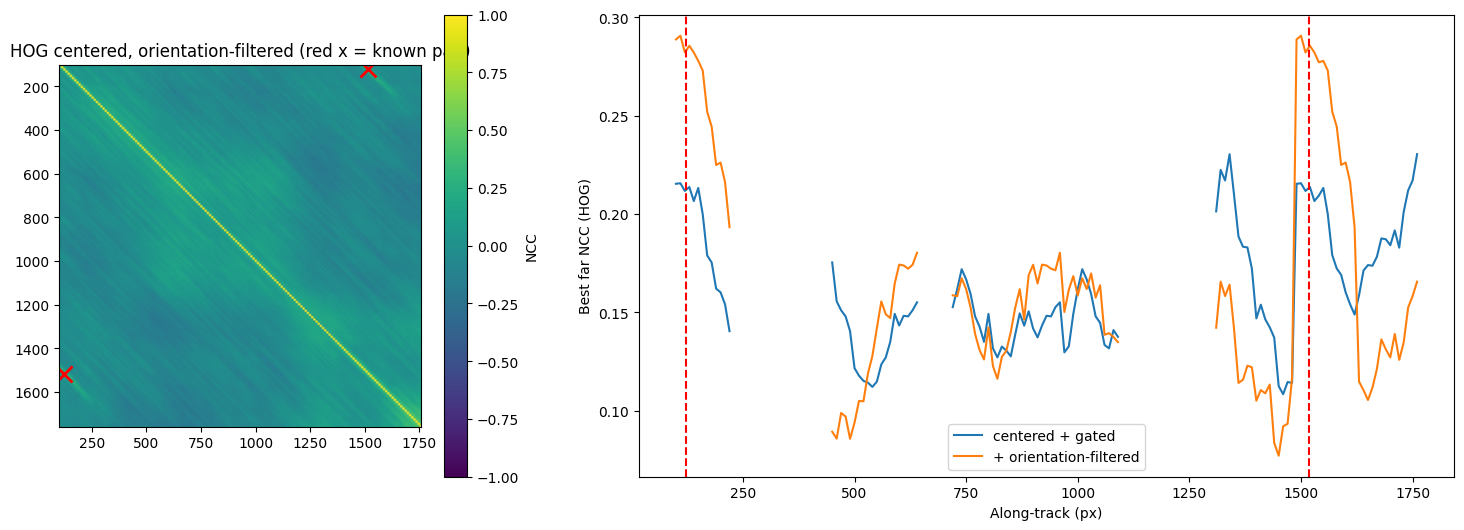

In [29]:
# HOG orientation-filtered: drop bins for edges parallel to the taxiway (gradient ~90 deg, across-track)
# cv2 HOG: 9 unsigned bins, centers 10, 30, ..., 170 deg, bins innermost in the descriptor
# NOTE: drops bins 3-5 (70, 90, 110 deg) -> keeps gradients within ~60 deg of along-track; cutoff is a choice
# NOTE: block normalization was done with all 9 bins, before dropping
keep_bins = [0, 1, 2, 6, 7, 8]
feats_o = feats_hog.reshape(len(feats_hog), -1, 9)[:, :, keep_bins].reshape(len(feats_hog), -1)
S_hog_o = ncc_matrix(feats_o - feats_o.mean(axis=0)) # Centered, same as above
print("NCC at known pair (HOG centered, orientation-filtered):", S_hog_o[i_known[0], i_known[1]])

best_far_o = np.where(far & keep[None, :], S_hog_o, -np.inf).max(axis=1)
best_far_o[~keep] = np.nan # Same gate as above

fig, axs = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1.8]})
im = axs[0].imshow(S_hog_o, cmap='viridis', vmin=-1, vmax=1, extent=[c_hog[0], c_hog[-1], c_hog[-1], c_hog[0]])
axs[0].plot(s_known[[0, 1]], s_known[[1, 0]], 'rx', ms=12, mew=2)
axs[0].set_title("HOG centered, orientation-filtered (red x = known pair)")
fig.colorbar(im, ax=axs[0], label="NCC")

axs[1].plot(c_hog, best_far_c, label='centered + gated')
axs[1].plot(c_hog, best_far_o, label='+ orientation-filtered')
for s in s_known:
    axs[1].axvline(s, color='r', ls='--')
axs[1].legend()
axs[1].set_xlabel("Along-track (px)")
axs[1].set_ylabel("Best far NCC (HOG)")

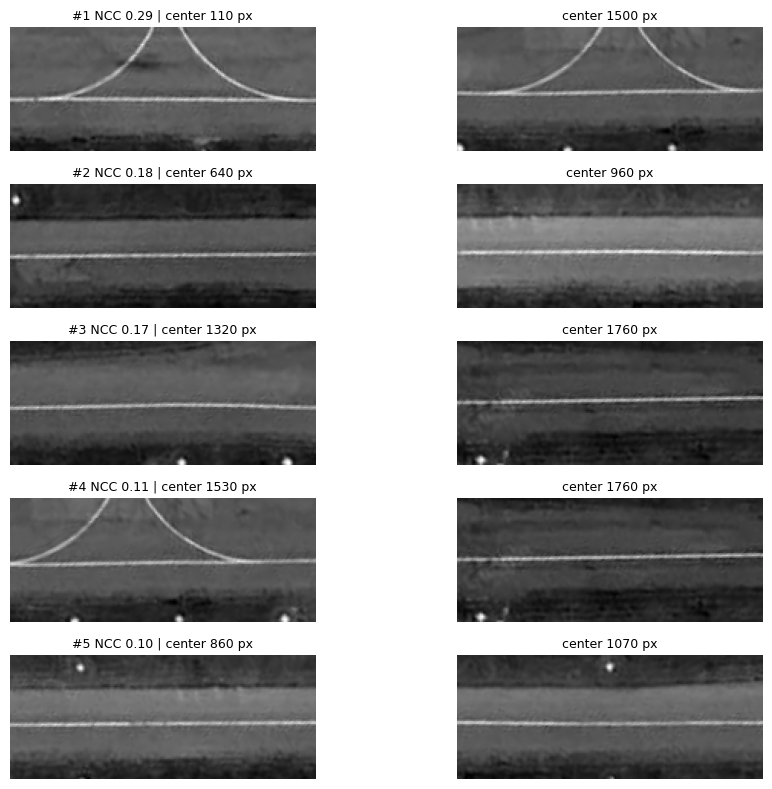

In [31]:
# Top-k distant pairs (HOG orientation filtered), shown as side-by-side tiles
# Both tiles must pass the gate; skip pairs within L of an already-picked pair (same as DINOv2 cell)
# NOTE: grayscale strip (strip_rgb is only built in the DINOv2 section)
k = 5
iu, ju = np.where(np.triu(far & keep[:, None] & keep[None, :]))
order = np.argsort(S_hog_o[iu, ju])[::-1]

picked = []
for o in order:
    i, j = iu[o], ju[o]
    if all(abs(starts_hog[i] - starts_hog[a]) > L or abs(starts_hog[j] - starts_hog[b]) > L for a, b in picked):
        picked.append((i, j))
    if len(picked) == k:
        break

fig, axs = plt.subplots(k, 2, figsize=(10, 1.6*k))
for r, (i, j) in enumerate(picked):
    for a, t in zip(axs[r], (i, j)):
        a.imshow(strip[:, starts_hog[t]:starts_hog[t] + L], cmap='gray')
        a.set_title(f"center {c_hog[t]:.0f} px", fontsize=9)
        a.axis('off')
    axs[r, 0].set_title(f"#{r+1} NCC {S_hog_o[i, j]:.2f} | center {c_hog[i]:.0f} px", fontsize=9)
plt.tight_layout()

## DINOv2 tile self-similarity

In [12]:
# DINOv2 ViT-S/14 (downloads ~85 MB of weights on first run, then cached)
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').cuda().eval()

# RGB strip, same centerline + half-width as the grayscale strip
strip_rgb = np.stack([rectify_strip(sat_rgb[..., k].astype(np.float32) / 255, p0, p1, half_w)[0] for k in range(3)], axis=-1)

Using cache found in /home/daniel-choate/.cache/torch/hub/facebookresearch_dinov2_main
/home/daniel-choate/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/daniel-choate/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/daniel-choate/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


1x | dims: 32256 | NCC at known pair: 0.296
2x | dims: 133632 | NCC at known pair: 0.280


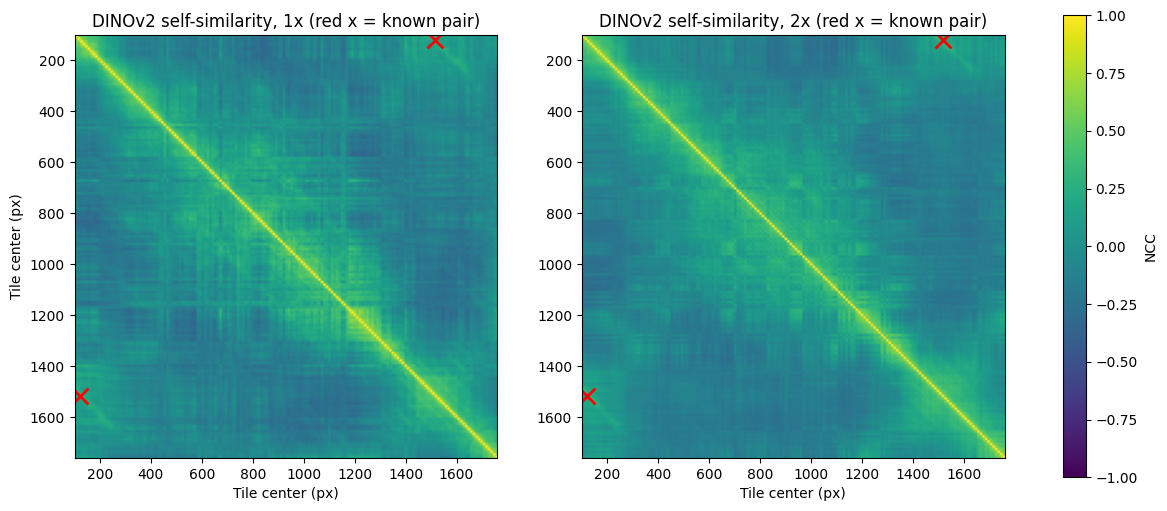

In [12]:
# DINOv2 patch-grid per tile at 1x and 2x upsample (same strip, L, stride) -> NCC
# Features centered over all tiles first (removes shared pavement/grass component)
# NOTE: mean is over this strip's tiles only, so the "background" depends on the strip analyzed
S_dino = {}
for sc in [1, 2]:
    feats_d, starts_d = tile_dino(strip_rgb, L, stride, model, scale=sc)
    S_dino[sc] = ncc_matrix(feats_d - feats_d.mean(axis=0))
    print(f"{sc}x | dims: {feats_d.shape[1]} | NCC at known pair: {S_dino[sc][i_known[0], i_known[1]]:.3f}")
c_dino = starts_d + L/2

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for a, (sc, S_d) in zip(axs, S_dino.items()):
    im = a.imshow(S_d, cmap='viridis', vmin=-1, vmax=1, extent=[c_dino[0], c_dino[-1], c_dino[-1], c_dino[0]])
    a.plot(s_known[[0, 1]], s_known[[1, 0]], 'rx', ms=12, mew=2)
    a.set_title(f"DINOv2 self-similarity, {sc}x (red x = known pair)")
    a.set_xlabel("Tile center (px)")
axs[0].set_ylabel("Tile center (px)")
fig.colorbar(im, ax=axs, label="NCC")

Text(0, 0.5, 'Best far NCC (DINOv2)')

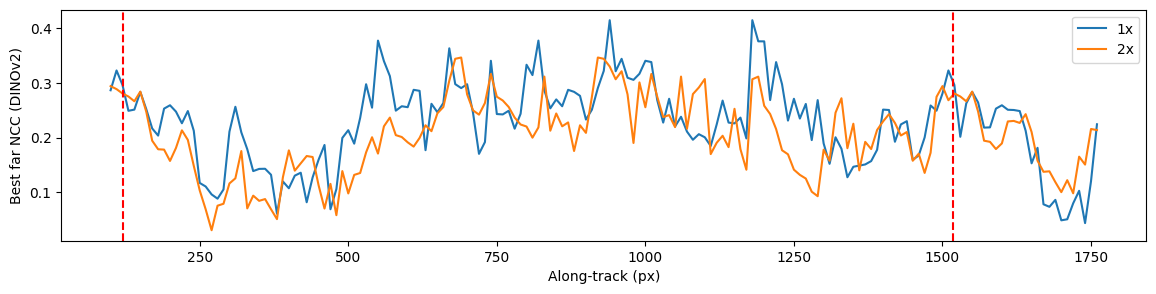

In [13]:
# Best far match, DINOv2 (both scales)
plt.figure(figsize=(14, 3))
for sc, S_d in S_dino.items():
    plt.plot(c_dino, np.where(far, S_d, -np.inf).max(axis=1), label=f"{sc}x")
for s in s_known:
    plt.axvline(s, color='r', ls='--')
plt.legend()
plt.xlabel("Along-track (px)")
plt.ylabel("Best far NCC (DINOv2)")

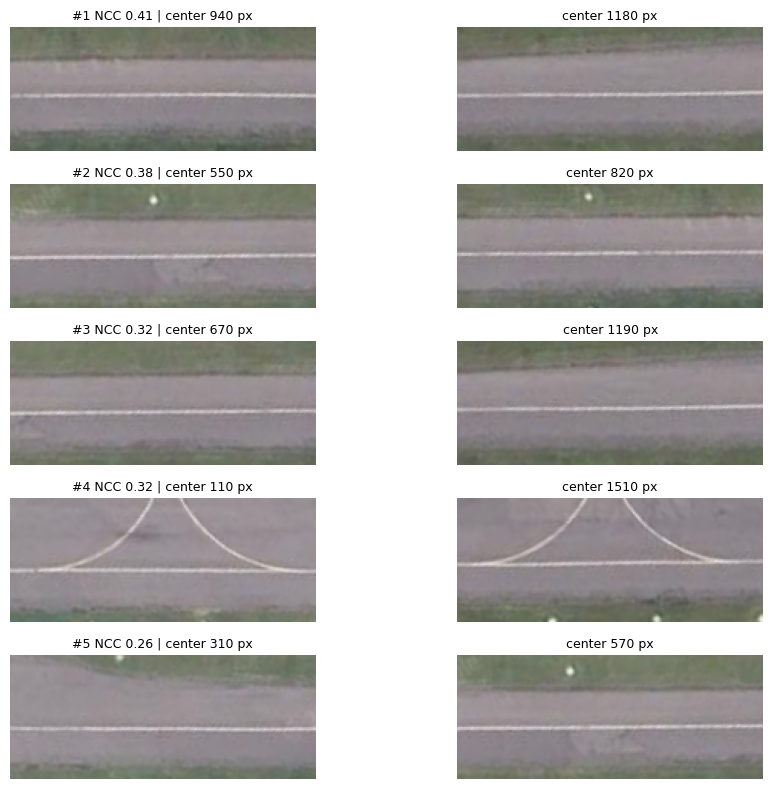

In [14]:
# Top-k distant pairs (DINOv2 1x), shown as side-by-side tiles
# Skip pairs within L of an already-picked pair (an off-diagonal streak repeats the same match)
k = 5
S_d = S_dino[1]
iu, ju = np.where(np.triu(far))
order = np.argsort(S_d[iu, ju])[::-1]

picked = []
for o in order:
    i, j = iu[o], ju[o]
    if all(abs(starts_d[i] - starts_d[a]) > L or abs(starts_d[j] - starts_d[b]) > L for a, b in picked):
        picked.append((i, j))
    if len(picked) == k:
        break

fig, axs = plt.subplots(k, 2, figsize=(10, 1.6*k))
for r, (i, j) in enumerate(picked):
    for a, t in zip(axs[r], (i, j)):
        a.imshow(strip_rgb[:, starts_d[t]:starts_d[t] + L])
        a.set_title(f"center {c_dino[t]:.0f} px", fontsize=9)
        a.axis('off')
    axs[r, 0].set_title(f"#{r+1} NCC {S_d[i, j]:.2f} | center {c_dino[i]:.0f} px", fontsize=9)
plt.tight_layout()